<a href="https://colab.research.google.com/github/Claudio-Ferriz/Proyecto-OP/blob/main/Proyecto_OP_Mejorado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de encuestas y resultados electorales por la Ciudad Autónoma de Buenos Aires (CABA)
Este notebook realiza un análisis integral que incluye:
1. **Carga y limpieza de datos**
2. **Análisis exploratorio (EDA)**


---
## 0. Configuración e Importación de Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Estilo global de visualizaciones
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_style('whitegrid')
PALETTE = 'tab10'

print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


---
## 1. Carga y Limpieza de Datos

In [2]:
# --- Encuestas en CABA ---
df_encuestas = pd.read_excel(
    'https://github.com/Claudio-Ferriz/Proyecto-OP/raw/refs/heads/main/Encuentas%20en%20CABA.xlsx'
)

# Eliminar columnas 'Unnamed'
df_encuestas = df_encuestas.drop(columns=[c for c in df_encuestas.columns if c.startswith('Unnamed')])

print(f'📊 Encuestas en CABA: {df_encuestas.shape[0]:,} registros | {df_encuestas.shape[1]} columnas')
df_encuestas.head(3)

📊 Encuestas en CABA: 2 registros | 14 columnas


,Localidad,Tipo de Encuesta,Tamaño de la muestra,Margen de error (%),Consultora,Link,Mes,Fecha,Voto en 2027 como Continuidad,Voto en 2027 como Cambio de Rumbo,Indice Desarrollo Humano,PBI per capita (PPA),Tasa Desempleo,Inflación
0,CABA,NaN,1130,NaN,DC Consultores,https://www.perfil.com/noticias/politica/encue...,Junio,2026-06-16,"52,7","47,3",NaN,NaN,NaN,NaN
1,CABA,NaN,1360,NaN,DC Consultores,https://www.perfil.com/noticias/politica/encue...,Julio,2026-07-22,"51,7","48,3",NaN,NaN,NaN,NaN


In [3]:
# --- Encuesta de intención de voto por CABA ---
df_encuesta_intención_voto = pd.read_excel(
    'https://github.com/Claudio-Ferriz/Proyecto-OP/raw/refs/heads/main/Encuestas%20de%20intenci%C3%B3n%20de%20voto%20por%20CABA%20.xlsx'
)

print(f'📊 Encuesta de intención de voto por CABA: {df_encuesta_intención_voto.shape[0]:,} registros | {df_encuesta_intención_voto.shape[1]} columnas')
df_encuesta_intención_voto.head(3)

📊 Encuesta de intención de voto por CABA: 2 registros | 20 columnas


,Localidad,Tipo de Encuesta,Tamaño de la muestra,Margen de error (%),Consultora,Link,Mes,Fecha,Leandro Santoro,Jorge Macri,Patricia Bullrich,Victoria Villarruel,Peronismo,PRO,La Libertad Avanza,Opción de centro derecha,Indice Desarrollo Humano,PBI per capita (PPA),Tasa Desempleo,Inflación
0,CABA,NaN,1360,NaN,DC Consultores,https://www.perfil.com/noticias/politica/encue...,Julio,2026-07-22,NaN,NaN,NaN,NaN,"19,8","26,7","30,1","23,4",NaN,NaN,NaN,NaN
1,CABA,NaN,918,"2,5",DC Consultores,https://www.perfil.com/noticias/amp/politica/e...,Agosto,2026-08-27,"19,7","31,2","32,8","16,4","13,8","38,4","14,2","33,6",NaN,NaN,NaN,NaN


---
## 2. Preparación de datos para las visualizaciones

Los Excel traen los porcentajes como **texto con coma decimal** (por ejemplo `"52,7"`), así que primero los convertimos a número. También definimos la paleta de colores y unas funciones de formato en español que reutilizan todos los gráficos.

In [4]:
# ============================================================
# 2. PREPARACIÓN DE DATOS Y ESTILO
# ============================================================
import textwrap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# --- Conversión de "52,7" (texto) -> 52.7 (número) ---
def a_numero(serie):
    return pd.to_numeric(serie.astype(str).str.replace(',', '.', regex=False), errors='coerce')

COL_CONT   = 'Voto en 2027 como Continuidad'
COL_CAMBIO = 'Voto en 2027 como Cambio de Rumbo'
PARTIDOS   = ['Peronismo', 'PRO', 'La Libertad Avanza', 'Opción de centro derecha']
CANDIDATOS = ['Leandro Santoro', 'Jorge Macri', 'Patricia Bullrich', 'Victoria Villarruel']

enc = df_encuestas.copy()
vot = df_encuesta_intención_voto.copy()

for c in [COL_CONT, COL_CAMBIO]:
    enc[c] = a_numero(enc[c])
for c in PARTIDOS + CANDIDATOS + ['Margen de error (%)']:
    vot[c] = a_numero(vot[c])
enc['Fecha'] = pd.to_datetime(enc['Fecha'])
vot['Fecha'] = pd.to_datetime(vot['Fecha'])

# --- Paleta y estilo ---
FONDO, TEXTO, GRIS, PISTA = '#FFFFFF', '#1F2937', '#6B7280', '#EEF0F3'
COLOR_CONT, COLOR_CAMBIO = '#1D4E89', '#E4572E'
COLOR_PARTIDO = {'Peronismo': '#4BA3E3', 'PRO': '#F5B700',
                 'La Libertad Avanza': '#6C3FB5', 'Opción de centro derecha': '#2A9D8F'}
COLOR_CANDIDATO = {'Leandro Santoro': '#4BA3E3', 'Jorge Macri': '#F5B700',
                   'Patricia Bullrich': '#6C3FB5', 'Victoria Villarruel': '#D1593F'}

# --- Formatos en español ---
def fmt(v, dec=1):
    return f'{v:.{dec}f}'.replace('.', ',')

def fmt_s(v, dec=1):                      # con signo: +1,0 / −6,0
    return f'{v:+.{dec}f}'.replace('.', ',').replace('-', '−')

def fmt_n(n):
    return f'{int(n):,}'.replace(',', '.')

def titulo_panel(fila):
    return f"{fila['Mes']} {fila['Fecha']:%Y}"

def descripcion(fila):
    return f"{fila['Consultora']} · n = {fmt_n(fila['Tamaño de la muestra'])} · {fila['Fecha']:%d/%m/%Y}"

def pie_figura(fig, texto):
    fig.text(0.5, 0.012, texto, ha='center', fontsize=9.5, color=GRIS)

# --- Ficha técnica de los relevamientos disponibles ---
ficha = (pd.concat([enc, vot])
           .drop_duplicates(subset='Fecha')
           [['Fecha', 'Mes', 'Consultora', 'Tamaño de la muestra', 'Margen de error (%)']]
           .sort_values('Fecha').reset_index(drop=True))
ficha['Fecha'] = ficha['Fecha'].dt.strftime('%d/%m/%Y')
ficha['Margen de error (%)'] = ficha['Margen de error (%)'].map(lambda v: '—' if pd.isna(v) else f'±{fmt(v)}')
print('✅ Datos convertidos y estilo definido')
ficha

✅ Datos convertidos y estilo definido


,Fecha,Mes,Consultora,Tamaño de la muestra,Margen de error (%)
0,16/06/2026,Junio,DC Consultores,1130,—
1,22/07/2026,Julio,DC Consultores,1360,—
2,27/08/2026,Agosto,DC Consultores,918,"±2,5"


---
## 3. Voto en 2027: Continuidad vs. Cambio de Rumbo
Un gráfico circular por relevamiento (`df_encuestas`). En el centro de cada uno se muestra la ventaja en **puntos porcentuales (pp)**.

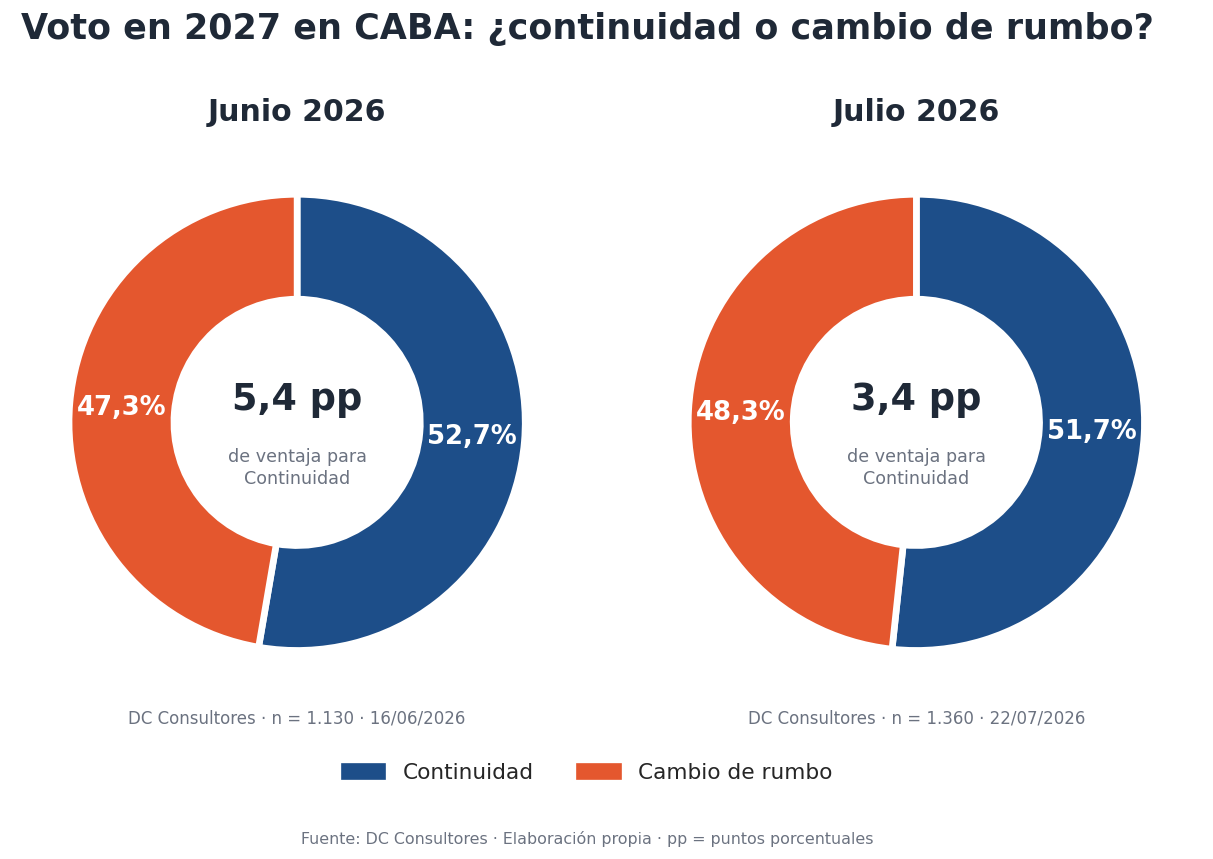

In [5]:
# ============================================================
# GRÁFICO 1 · Continuidad vs. Cambio de Rumbo (un círculo por registro)
# ============================================================
def donut(ax, fila):
    valores = [fila[COL_CONT], fila[COL_CAMBIO]]
    colores = [COLOR_CONT, COLOR_CAMBIO]
    wedges, _ = ax.pie(valores, colors=colores, startangle=90, counterclock=False,
                       wedgeprops=dict(width=0.46, edgecolor=FONDO, linewidth=4))
    for w, v in zip(wedges, valores):
        ang = np.deg2rad((w.theta1 + w.theta2) / 2)
        ax.text(0.77 * np.cos(ang), 0.77 * np.sin(ang), f'{fmt(v)}%',
                ha='center', va='center', fontsize=15.5, fontweight='bold', color='white')
    ventaja = valores[0] - valores[1]
    lider = 'Continuidad' if ventaja > 0 else 'Cambio de rumbo'
    ax.text(0, 0.10, f'{fmt(abs(ventaja))} pp', ha='center', va='center',
            fontsize=22, fontweight='bold', color=TEXTO)
    ax.text(0, -0.20, f'de ventaja para\n{lider}', ha='center', va='center',
            fontsize=10.5, color=GRIS, linespacing=1.3)
    ax.set_title(titulo_panel(fila), fontsize=18, fontweight='bold', color=TEXTO, pad=10)
    ax.text(0, -1.30, descripcion(fila), ha='center', va='center', fontsize=10, color=GRIS)

fig, axes = plt.subplots(1, 2, figsize=(13, 7.2), facecolor=FONDO)
for ax, (_, fila) in zip(axes, enc.iterrows()):
    donut(ax, fila)

fig.suptitle('Voto en 2027 en CABA: ¿continuidad o cambio de rumbo?',
             fontsize=21, fontweight='bold', color=TEXTO, y=0.975)
fig.legend(handles=[Patch(color=COLOR_CONT, label='Continuidad'),
                    Patch(color=COLOR_CAMBIO, label='Cambio de rumbo')],
           loc='lower center', ncol=2, frameon=False, fontsize=13, bbox_to_anchor=(0.5, 0.06))
pie_figura(fig, 'Fuente: DC Consultores · Elaboración propia · pp = puntos porcentuales')
fig.subplots_adjust(top=0.83, bottom=0.17, wspace=0.05)
plt.show()

---
## 4. Intención de voto por espacio político
Un gráfico de barras horizontales por cada relevamiento de `df_encuesta_intención_voto` (Peronismo, PRO, La Libertad Avanza y Opción de centro derecha). Ambos usan la **misma escala** para poder compararlos a simple vista.

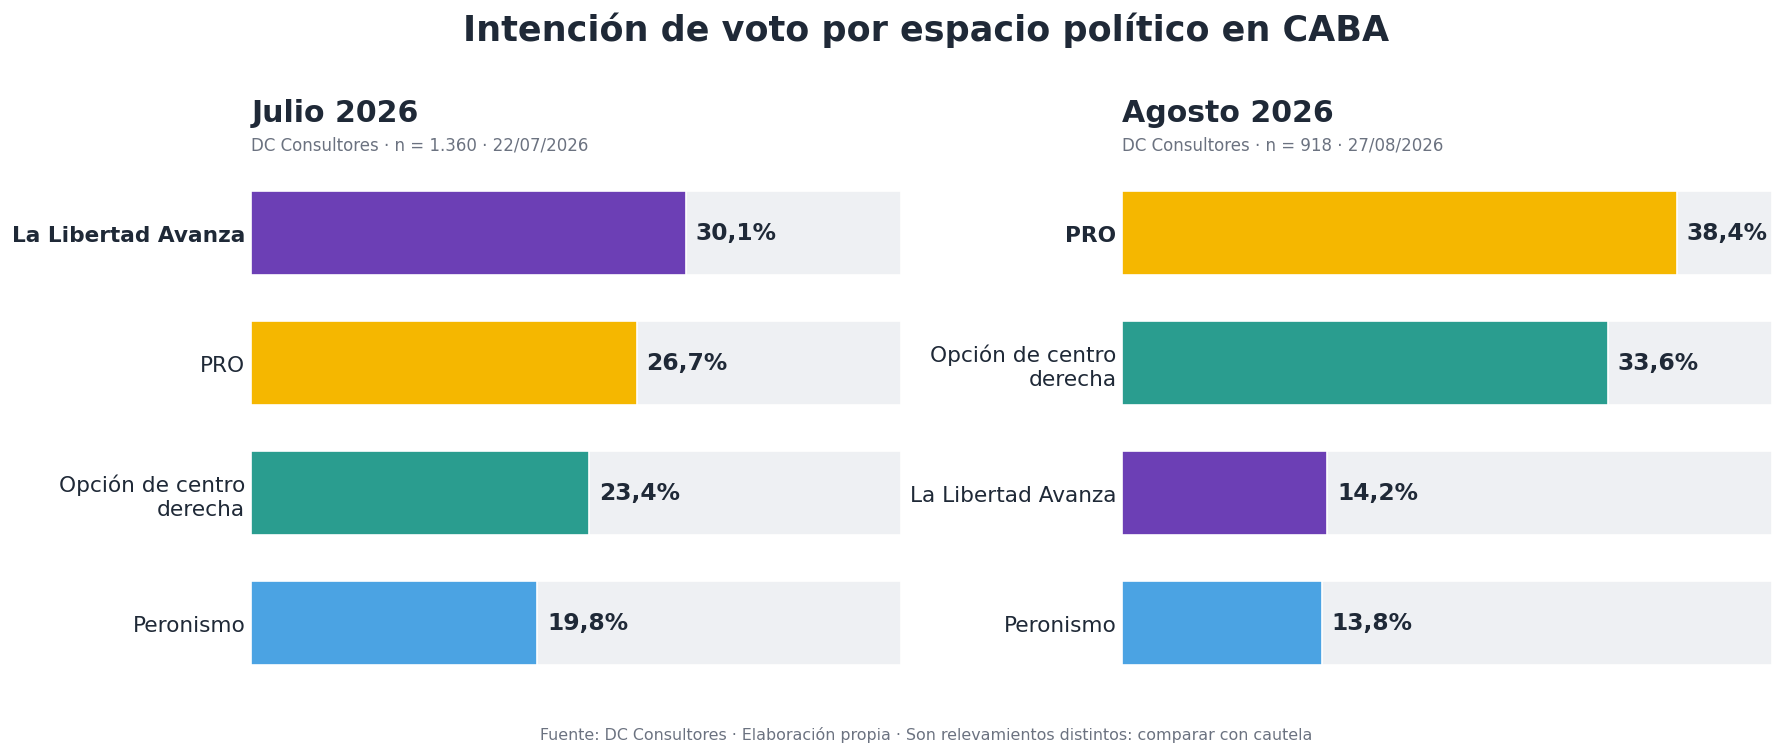

In [6]:
# ============================================================
# Función reutilizable para barras horizontales
# ============================================================
def barras_h(ax, serie, colores, xmax, titulo, subtitulo):
    s = serie.sort_values(ascending=True)            # el mayor queda arriba
    claves = list(s.index)
    etiquetas = [textwrap.fill(k, 18) for k in claves]
    pos = np.arange(len(s))
    ax.barh(pos, [xmax] * len(s), color=PISTA, height=0.64, zorder=0)          # pista gris de fondo
    barras = ax.barh(pos, s.values, color=[colores[k] for k in claves], height=0.64, zorder=2)
    for b, v in zip(barras, s.values):
        ax.text(v + xmax * 0.015, b.get_y() + b.get_height() / 2, f'{fmt(v)}%',
                va='center', ha='left', fontsize=14, fontweight='bold', color=TEXTO, zorder=3)
    ax.set_yticks(pos)
    ax.set_yticklabels(etiquetas)
    ax.get_yticklabels()[-1].set_fontweight('bold')                             # resalta al líder
    ax.set_xlim(0, xmax)
    ax.set_xticks([])
    ax.tick_params(axis='y', length=0, labelsize=13, labelcolor=TEXTO)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.grid(False)
    ax.set_title(titulo, loc='left', fontsize=18, fontweight='bold', color=TEXTO, pad=28)
    ax.text(0, 1.035, subtitulo, transform=ax.transAxes, fontsize=10, color=GRIS)

# ============================================================
# GRÁFICO 2 · Espacios políticos, un gráfico por registro
# ============================================================
xmax_part = np.ceil(vot[PARTIDOS].max().max() / 5) * 5 + 5      # escala común

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), facecolor=FONDO)
for ax, (_, fila) in zip(axes, vot.iterrows()):
    barras_h(ax, fila[PARTIDOS].astype(float), COLOR_PARTIDO, xmax_part,
             titulo_panel(fila), descripcion(fila))

fig.suptitle('Intención de voto por espacio político en CABA',
             fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, 'Fuente: DC Consultores · Elaboración propia · Son relevamientos distintos: comparar con cautela')
fig.subplots_adjust(top=0.78, bottom=0.08, wspace=0.34, left=0.125, right=0.97)
plt.show()

---
## 5. Intención de voto por candidato (segundo registro)
Solo el segundo relevamiento (agosto) trae datos por candidato. Si la diferencia entre los dos primeros es menor al margen de error informado, el gráfico lo aclara.

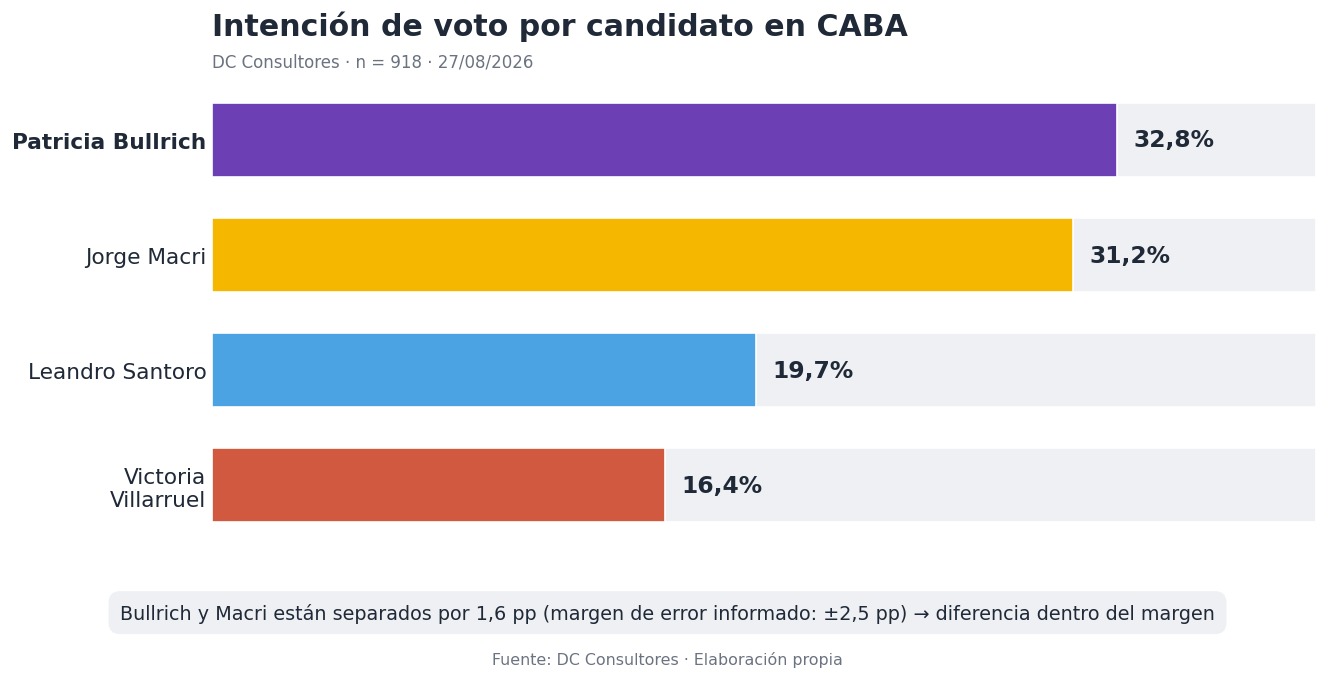

In [7]:
# ============================================================
# GRÁFICO 3 · Candidatos (segundo registro)
# ============================================================
fila = vot.iloc[1]
cand = fila[CANDIDATOS].astype(float)
xmax_cand = np.ceil(cand.max() / 5) * 5 + 5

fig, ax = plt.subplots(figsize=(11.5, 6), facecolor=FONDO)
barras_h(ax, cand, COLOR_CANDIDATO, xmax_cand,
         'Intención de voto por candidato en CABA', descripcion(fila))

# Nota sobre la diferencia entre los dos primeros
top2 = cand.nlargest(2)
gap = top2.iloc[0] - top2.iloc[1]
nombres = [n.split()[-1] for n in top2.index]
nota = f'{nombres[0]} y {nombres[1]} están separados por {fmt(gap)} pp'
moe = fila['Margen de error (%)']
if pd.notna(moe):
    nota += f' (margen de error informado: ±{fmt(moe)} pp)' + (' → diferencia dentro del margen' if gap <= moe else '')
fig.text(0.5, 0.075, nota, ha='center', fontsize=11.5, color=TEXTO,
         bbox=dict(boxstyle='round,pad=0.6', fc=PISTA, ec='none'))
pie_figura(fig, 'Fuente: DC Consultores · Elaboración propia')
fig.subplots_adjust(top=0.82, bottom=0.18, left=0.17, right=0.97)
plt.show()

---
## 6. Gráficos adicionales con los datos disponibles
**6.1** Cómo cambió la brecha entre continuidad y cambio de rumbo.  
**6.2** Cómo se movió cada espacio político entre julio y agosto (gráfico de mancuernas).

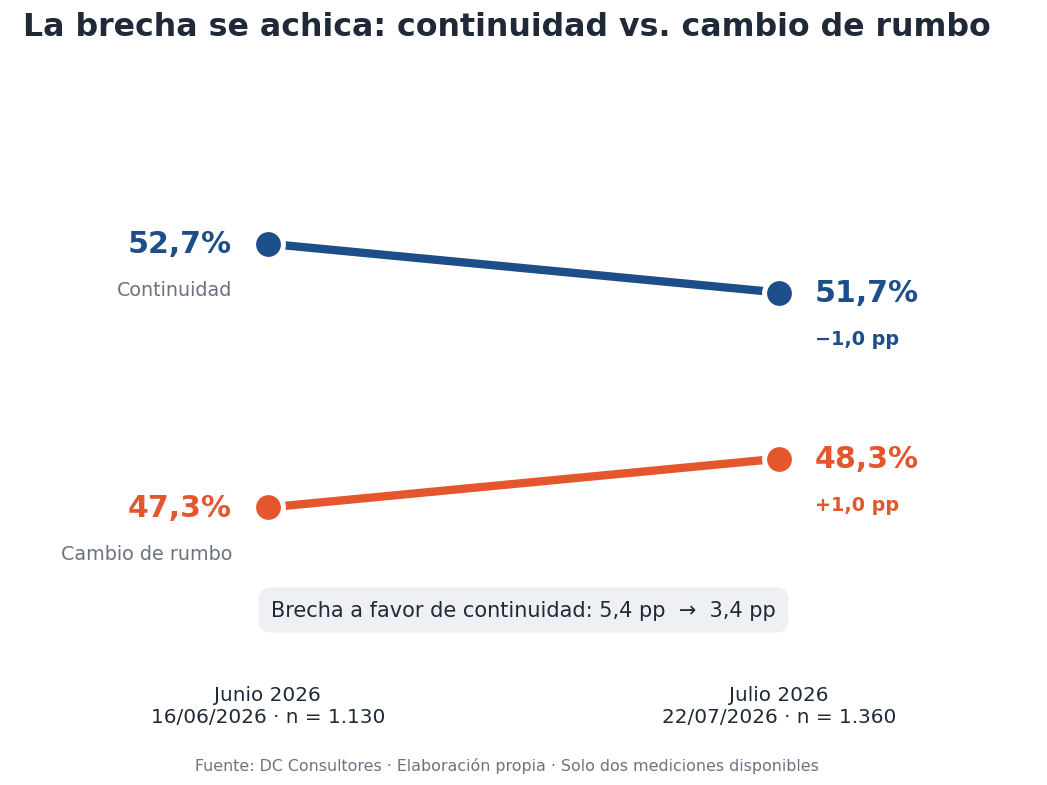

In [8]:
# ============================================================
# EXTRA 6.1 · Evolución Continuidad vs. Cambio de Rumbo
# ============================================================
f0, f1 = enc.iloc[0], enc.iloc[1]
fig, ax = plt.subplots(figsize=(11, 6.6), facecolor=FONDO)

for col, color, nombre in [(COL_CONT, COLOR_CONT, 'Continuidad'),
                           (COL_CAMBIO, COLOR_CAMBIO, 'Cambio de rumbo')]:
    y0, y1 = f0[col], f1[col]
    ax.plot([0, 1], [y0, y1], color=color, lw=5, solid_capstyle='round', zorder=2)
    ax.scatter([0, 1], [y0, y1], s=320, color=color, edgecolor='white', linewidth=3, zorder=3)
    ax.text(-0.07, y0, f'{fmt(y0)}%', ha='right', va='center', fontsize=18, fontweight='bold', color=color)
    ax.text(-0.07, y0 - 0.95, nombre, ha='right', va='center', fontsize=11.5, color=GRIS)
    ax.text(1.07, y1, f'{fmt(y1)}%', ha='left', va='center', fontsize=18, fontweight='bold', color=color)
    ax.text(1.07, y1 - 0.95, f'{fmt_s(y1 - y0)} pp', ha='left', va='center', fontsize=11.5,
            color=color, fontweight='bold')

b0, b1 = abs(f0[COL_CONT] - f0[COL_CAMBIO]), abs(f1[COL_CONT] - f1[COL_CAMBIO])
lider = 'continuidad' if f1[COL_CONT] > f1[COL_CAMBIO] else 'cambio de rumbo'
ax.text(0.5, 45.2, f'Brecha a favor de {lider}: {fmt(b0)} pp  →  {fmt(b1)} pp',
        ha='center', va='center', fontsize=12.5, color=TEXTO,
        bbox=dict(boxstyle='round,pad=0.6', fc=PISTA, ec='none'))

ax.set_xticks([0, 1])
ax.set_xticklabels([f"{titulo_panel(f)}\n{f['Fecha']:%d/%m/%Y} · n = {fmt_n(f['Tamaño de la muestra'])}" for f in (f0, f1)],
                   fontsize=12, color=TEXTO)
ax.tick_params(axis='x', length=0, pad=10)
ax.set_yticks([])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(44, 56)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.suptitle('La brecha se achica: continuidad vs. cambio de rumbo' if b1 < b0
             else 'Continuidad vs. cambio de rumbo: evolución entre relevamientos',
             fontsize=19, fontweight='bold', color=TEXTO, y=0.97)
pie_figura(fig, 'Fuente: DC Consultores · Elaboración propia · Solo dos mediciones disponibles')
fig.subplots_adjust(top=0.88, bottom=0.14)
plt.show()

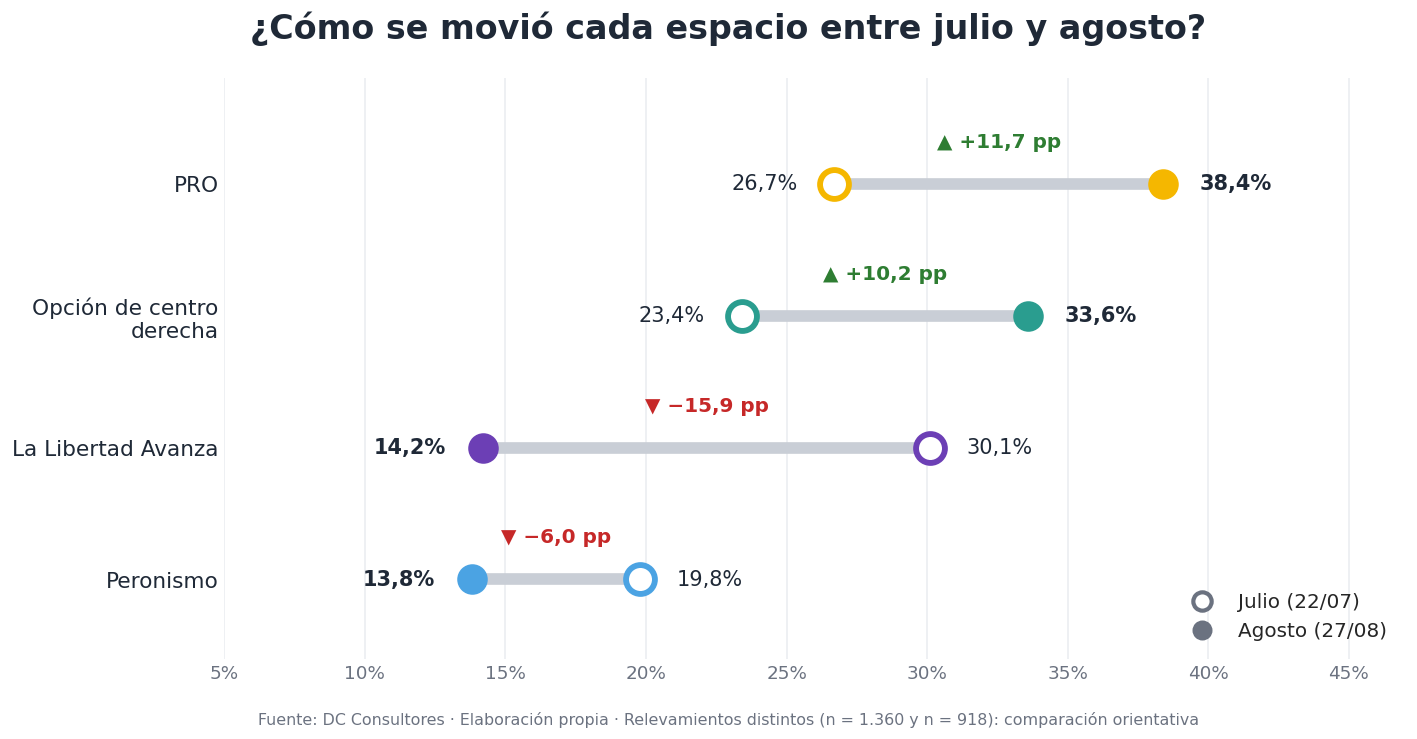

In [9]:
# ============================================================
# EXTRA 6.2 · Cambio por espacio político: julio → agosto (mancuernas)
# ============================================================
v0, v1 = vot.iloc[0], vot.iloc[1]
orden = list(v1[PARTIDOS].astype(float).sort_values().index)       # ordenado por agosto

fig, ax = plt.subplots(figsize=(12, 6.2), facecolor=FONDO)
for i, p in enumerate(orden):
    a, b = float(v0[p]), float(v1[p])
    ax.plot([a, b], [i, i], color='#C9CED6', lw=7, solid_capstyle='round', zorder=1)
    ax.scatter(a, i, s=300, facecolor='white', edgecolor=COLOR_PARTIDO[p], linewidth=3.5, zorder=3)
    ax.scatter(b, i, s=300, color=COLOR_PARTIDO[p], zorder=4)
    for valor, es_agosto in [(a, False), (b, True)]:
        izq = valor == min(a, b)
        ax.text(valor + (-1.3 if izq else 1.3), i, f'{fmt(valor)}%', ha='right' if izq else 'left',
                va='center', fontsize=12.5, color=TEXTO, fontweight='bold' if es_agosto else 'normal')
    flecha = '▲' if b > a else '▼'
    ax.text((a + b) / 2, i + 0.32, f'{flecha} {fmt_s(b - a)} pp', ha='center', va='center',
            fontsize=12, fontweight='bold', color='#2E7D32' if b > a else '#C62828')

ax.set_yticks(range(len(orden)))
ax.set_yticklabels([textwrap.fill(p, 18) for p in orden], fontsize=13, color=TEXTO)
ax.tick_params(axis='y', length=0)
ax.set_xlim(5, 47)
ax.set_ylim(-0.6, len(orden) - 0.2)
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0f}%')
ax.tick_params(axis='x', labelsize=11, colors=GRIS, length=0)
ax.yaxis.grid(False)
ax.xaxis.grid(True, color=PISTA, lw=1.2)
ax.set_axisbelow(True)
for sp in ax.spines.values():
    sp.set_visible(False)

ax.legend(handles=[Line2D([0], [0], marker='o', ls='', mfc='white', mec=GRIS, mew=2.5, ms=11,
                          label=f"{v0['Mes']} ({v0['Fecha']:%d/%m})"),
                   Line2D([0], [0], marker='o', ls='', color=GRIS, ms=11,
                          label=f"{v1['Mes']} ({v1['Fecha']:%d/%m})")],
          loc='lower right', frameon=False, fontsize=12)
fig.suptitle('¿Cómo se movió cada espacio entre julio y agosto?',
             fontsize=20, fontweight='bold', color=TEXTO, y=0.97)
pie_figura(fig, f"Fuente: DC Consultores · Elaboración propia · Relevamientos distintos (n = {fmt_n(v0['Tamaño de la muestra'])} y n = {fmt_n(v1['Tamaño de la muestra'])}): comparación orientativa")
fig.subplots_adjust(top=0.88, bottom=0.10, left=0.15, right=0.97)
plt.show()

In [10]:
# ============================================================
# Lectura rápida (se calcula sola con los datos)
# ============================================================
print('📌 LECTURA RÁPIDA\n')
for _, f in enc.iterrows():
    lider = 'Continuidad' if f[COL_CONT] > f[COL_CAMBIO] else 'Cambio de rumbo'
    print(f"• {titulo_panel(f)}: {lider} lidera por {fmt(abs(f[COL_CONT] - f[COL_CAMBIO]))} pp "
          f"({fmt(f[COL_CONT])}% vs. {fmt(f[COL_CAMBIO])}%)")
for _, f in vot.iterrows():
    s = f[PARTIDOS].astype(float).sort_values(ascending=False)
    print(f"• {titulo_panel(f)} (espacios): lidera {s.index[0]} con {fmt(s.iloc[0])}%, seguido de {s.index[1]} ({fmt(s.iloc[1])}%)")
c = vot.iloc[1][CANDIDATOS].astype(float).sort_values(ascending=False)
print(f"• {titulo_panel(vot.iloc[1])} (candidatos): {c.index[0]} {fmt(c.iloc[0])}% · {c.index[1]} {fmt(c.iloc[1])}% · "
      f"{c.index[2]} {fmt(c.iloc[2])}% · {c.index[3]} {fmt(c.iloc[3])}%")

📌 LECTURA RÁPIDA

• Junio 2026: Continuidad lidera por 5,4 pp (52,7% vs. 47,3%)
• Julio 2026: Continuidad lidera por 3,4 pp (51,7% vs. 48,3%)
• Julio 2026 (espacios): lidera La Libertad Avanza con 30,1%, seguido de PRO (26,7%)
• Agosto 2026 (espacios): lidera PRO con 38,4%, seguido de Opción de centro derecha (33,6%)
• Agosto 2026 (candidatos): Patricia Bullrich 32,8% · Jorge Macri 31,2% · Leandro Santoro 19,7% · Victoria Villarruel 16,4%
